| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../12_DEEP_LEARNING/12_3_Deep_Learning_matematico.ipynb) | [⏩](../14_PROBLEMAS_INVERSOS/14_1_Problema_inverso.ipynb) |

# 13.1 Modelos físicos: balances, escalas y validación

**Objetivo del cuaderno.** construir modelos a partir de leyes y supuestos, adimensionalizar, verificar conservación y distinguir calibración de validación

**Antes de empezar:** ODE, unidades, energía y análisis numérico. Ejecuta las celdas de arriba hacia abajo. Los datos se generan localmente y la semilla hace repetible el experimento; las conclusiones numéricas corresponden a este conjunto de datos.

**Ruta de estudio:** primero formula el problema y entiende las ecuaciones; después compara las figuras con las predicciones teóricas; finalmente modifica un parámetro y resuelve los ejercicios. En cada gráfico distinguimos lo que demuestra el experimento de lo que requiere una hipótesis matemática.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'font.size': 11})
rng = np.random.default_rng(42)

## 1. Del fenómeno al modelo

Un modelo científico representa un fenómeno mediante variables, hipótesis y relaciones. Para formularlo, delimita un sistema, decide qué estado se observa, identifica entradas y escribe balances. Distingue parámetros medibles, parámetros efectivos y funciones desconocidas.

No hay una única ecuación útil para todo objetivo. Un modelo concentrado puede describir una temperatura media; una PDE puede ser necesaria para gradientes espaciales. La complejidad debe corresponder a la escala y precisión de la pregunta, no a la cantidad de ecuaciones disponibles.

Una ficha mínima incluye dominio, variables y unidades, condiciones iniciales/borde, ecuaciones, parámetros, rangos de validez y observables. SciML puede aprender componentes, pero no elimina la necesidad de esa ficha.

## 2. Conservación y constitutivas

Un balance genérico dice **acumulación = entradas − salidas + producción**. Conservación de masa, momento y energía organiza ecuaciones. Las relaciones constitutivas cierran el modelo: fuerza de resorte proporcional a desplazamiento, flujo térmico proporcional a gradiente, etc. Esas relaciones suelen ser aproximaciones con rango de validez.

En difusión, conservación y ley de Fourier producen $\rho c_p T_t=\nabla\cdot(k\nabla T)+q$. Para $k$ constante la difusividad es $\alpha=k/(\rho c_p)$, con unidades de longitud cuadrada/tiempo. Aprender $\alpha$ sin distinguirlo de $k$ o sin conocer $\rho c_p$ puede cambiar la interpretación del parámetro.

## 3. Ejemplo mecánico: masa, resorte y amortiguador

La segunda ley de Newton produce

$$m\ddot x+c\dot x+kx=F(t).$$

$x$ se mide en metros, $m$ en kg, $c$ en kg/s, $k$ en kg/s² y $F$ en newton. El modelo supone resorte lineal, amortiguamiento viscoso y una coordenada de movimiento. Un resorte no lineal o fricción seca requiere otra relación constitutiva.

Definiendo $v=\dot x$, obtenemos $\dot x=v$ y $\dot v=(F-cv-kx)/m$. La energía mecánica es $E=\tfrac12mv^2+\tfrac12kx^2$ y

$$\dot E=Fv-cv^2.$$

Sin fuerza externa ni amortiguamiento la energía se conserva; con $c>0$ disminuye. Esta identidad proporciona una comprobación independiente de la trayectoria.

## 4. Solución numérica y diagnóstico energético

Usamos tres amortiguamientos con la misma masa y rigidez. `solve_ivp` controla error local; ajustamos tolerancias y luego verificamos el balance energético en una malla de salida. La evaluación de balance usa cuadratura y tiene también su propio error.

c= 0.0 balance máximo= 9.827904712267355e-09
c= 0.4 balance máximo= 2.100459306139668e-05
c= 4.0 balance máximo= 6.145118751842843e-05


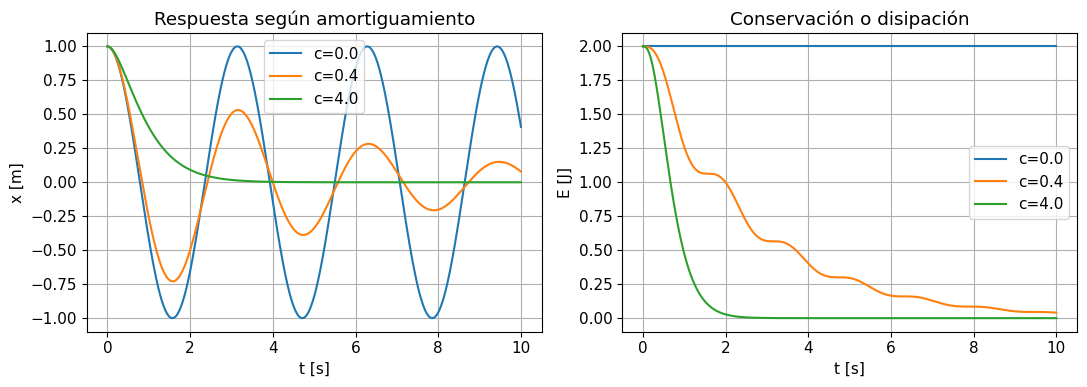

In [2]:
from scipy.integrate import solve_ivp, cumulative_trapezoid
m=1.;k=4.;x0=1.;v0=0.;times=np.linspace(0,10,1001)
solutions={}
for damping in [0.,0.4,4.]:
    def rhs(t,state):
        x,v=state;return [v,(-damping*v-k*x)/m]
    sol=solve_ivp(rhs,(times[0],times[-1]),[x0,v0],t_eval=times,rtol=1e-9,atol=1e-11)
    assert sol.success
    x,v=sol.y;energy=0.5*m*v*v+0.5*k*x*x
    dissipation=cumulative_trapezoid(damping*v*v,times,initial=0)
    balance=energy-energy[0]+dissipation
    solutions[damping]=(x,v,energy,balance)
    print('c=',damping,'balance máximo=',np.max(np.abs(balance)))
fig,ax=plt.subplots(1,2,figsize=(11,4))
for damping,(x,v,E,balance) in solutions.items():
    ax[0].plot(times,x,label=f'c={damping}');ax[1].plot(times,E,label=f'c={damping}')
ax[0].set(xlabel='t [s]',ylabel='x [m]',title='Respuesta según amortiguamiento')
ax[1].set(xlabel='t [s]',ylabel='E [J]',title='Conservación o disipación')
for a in ax:a.legend()
plt.tight_layout();plt.show()

**Interpretación.** El caso no amortiguado oscila sin perder energía; el viscoso pierde energía; el amortiguamiento crítico elimina oscilación para estos parámetros. Un error numérico pequeño no prueba que el resorte real sea lineal: valida el cálculo respecto al modelo elegido.

## 5. Adimensionalizar descubre grupos relevantes

La frecuencia natural es $\omega_n=\sqrt{k/m}$ y el amortiguamiento relativo es $\zeta=c/(2\sqrt{km})$. Con $\tau=\omega_n t$ y $q=x/X_0$, sin fuerza externa:

$$q''+2\zeta q'+q=0.$$

Primas ahora son respecto a $\tau$. Dos sistemas con distintas unidades y parámetros pero el mismo $\zeta$ y condiciones adimensionales comparten la misma trayectoria adimensional. Esta similitud reduce el número de variables relevantes para un modelo aprendido.

Para forcing la ecuación incluye $F/(kX_0)$. El grupo representa fuerza aplicada respecto a fuerza de resorte característica. Elegir escalas también hace explícito cuándo una contribución es despreciable.

## 6. Colapso de dos sistemas bajo la misma escala

El parecido viene de la ecuación escalada, no de un ajuste de datos.


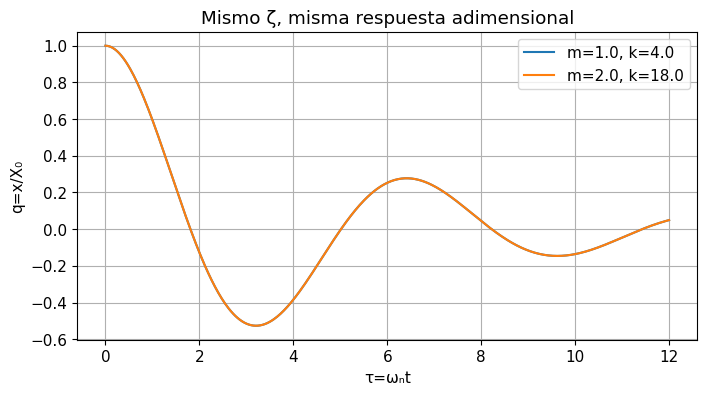

In [3]:
systems=[(1.,4.),(2.,18.)];zeta=0.2;tau=np.linspace(0,12,500)
for mass,stiffness in systems:
    wn=np.sqrt(stiffness/mass);damping=2*zeta*np.sqrt(mass*stiffness)
    physical_t=tau/wn
    def rhs(t,y):return [y[1],(-damping*y[1]-stiffness*y[0])/mass]
    sol=solve_ivp(rhs,(0,physical_t[-1]),[1,0],t_eval=physical_t,rtol=1e-9,atol=1e-11)
    plt.plot(tau,sol.y[0],label=f'm={mass}, k={stiffness}')
plt.xlabel('τ=ωₙt');plt.ylabel('q=x/X₀');plt.title('Mismo ζ, misma respuesta adimensional');plt.legend();plt.show()
print('El parecido viene de la ecuación escalada, no de un ajuste de datos.')

## 7. Otro balance: enfriamiento de un cuerpo concentrado

Si el interior de un cuerpo se considera a temperatura uniforme, un balance térmico da

$$m_b c_p\frac{dT}{dt}=-hA(T-T_\infty).$$

La solución es $T=T_\infty+(T_0-T_\infty)e^{-\beta t}$ con $\beta=hA/(m_bc_p)$. $\beta$ tiene unidades de tiempo inverso. El modelo concentrado es razonable cuando resistencia térmica interna es pequeña comparada con la externa; se suele analizar con el número de Biot $Bi=hL_c/k_s$, y $Bi\ll1$ favorece uniformidad.

No interpretaremos un ajuste perfecto de $\beta$ como identificación separada de $h,A,m_b,c_p$: el observable de este modelo depende de su combinación. Parámetros estructuralmente confundidos no se separan solo añadiendo más puntos de la misma curva.

## 8. Calibrar un modelo y validar el futuro

Generamos temperaturas con $\beta=0.35$ y ruido. Calibramos con tiempos tempranos y reservamos tiempos posteriores. Esta separación evalúa continuación temporal, mientras una separación aleatoria respondería otra pregunta.

β real/estimado: 0.35 0.3499589260805717
RMSE futuro: 0.42755440129685457


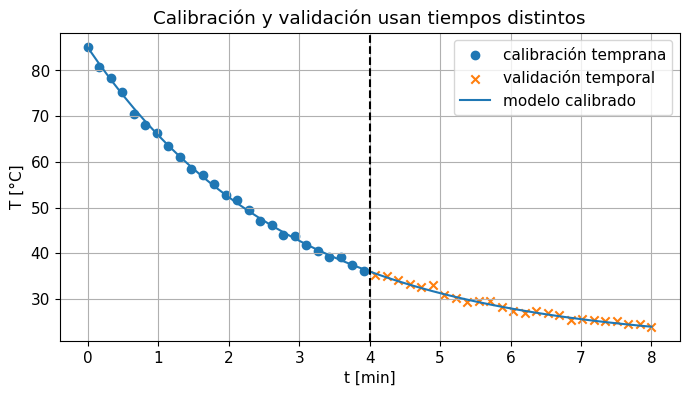

In [4]:
ambient=20.;initial=85.;beta_true=0.35
t_obs=np.linspace(0,8,50)
def cooling(t,beta):return ambient+(initial-ambient)*np.exp(-beta*t)
observed=cooling(t_obs,beta_true)+rng.normal(0,0.6,len(t_obs))
train=t_obs<=4
fit=optimize.least_squares(lambda b:cooling(t_obs[train],b[0])-observed[train],[0.2],bounds=(0,2))
assert fit.success
beta_hat=fit.x[0]
pred=cooling(t_obs,beta_hat)
plt.scatter(t_obs[train],observed[train],label='calibración temprana')
plt.scatter(t_obs[~train],observed[~train],marker='x',label='validación temporal')
plt.plot(t_obs,pred,label='modelo calibrado');plt.axvline(4,c='k',ls='--')
plt.xlabel('t [min]');plt.ylabel('T [°C]');plt.title('Calibración y validación usan tiempos distintos');plt.legend();plt.show()
print('β real/estimado:',beta_true,beta_hat)
print('RMSE futuro:',np.sqrt(np.mean((pred[~train]-observed[~train])**2)))

**Interpretación.** La ecuación extrapola el decaimiento porque su estructura lo impone. Si el ambiente cambia o aparece radiación significativa, un buen ajuste inicial puede fallar después. El conocimiento físico ayuda a extrapolar dentro de su dominio de validez; no elimina la necesidad de validación.

## 9. Error de discretización, observación y modelo

Tres errores distintos pueden coexistir: el solver aproxima una ecuación, el sensor aproxima una magnitud y la ecuación aproxima el fenómeno. Refinar tolerancias del solver solo reduce el primero. Añadir más datos con el mismo sensor sesgado no elimina ese sesgo. Un residual sistemático puede indicar física omitida.

Construimos un ejemplo de enfriamiento con un término cúbico adicional en la diferencia normalizada de temperatura. El término es una relación efectiva ilustrativa; no debe confundirse con la ley exacta de radiación de Stefan–Boltzmann, que depende de temperatura absoluta elevada a la cuarta potencia.

## 10. Detectar una discrepancia estructural

Para $\theta=(T-T_\infty)/(T_0-T_\infty)$ simulamos $\dot\theta=-\beta\theta-\gamma\theta^3$. Ajustamos un decaimiento puramente lineal con datos tempranos y revisamos tendencia residual. La respuesta no lineal cambia su tasa efectiva durante el enfriamiento.

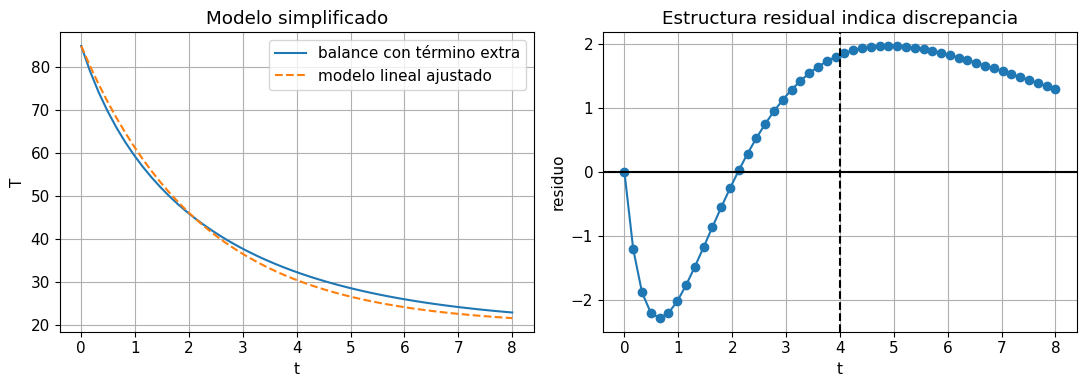

In [5]:
gamma=0.25
sol=solve_ivp(lambda t,z:-beta_true*z-gamma*z**3,(0,8),[1.],t_eval=t_obs,rtol=1e-9,atol=1e-11)
obs_nonlinear=ambient+(initial-ambient)*sol.y[0]
wrong_fit=optimize.least_squares(lambda b:cooling(t_obs[train],b[0])-obs_nonlinear[train],[0.4],bounds=(0,2))
pred_wrong=cooling(t_obs,wrong_fit.x[0])
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].plot(t_obs,obs_nonlinear,label='balance con término extra');ax[0].plot(t_obs,pred_wrong,'--',label='modelo lineal ajustado')
ax[0].set(xlabel='t',ylabel='T',title='Modelo simplificado');ax[0].legend()
ax[1].plot(t_obs,obs_nonlinear-pred_wrong,'o-');ax[1].axhline(0,c='k');ax[1].axvline(4,c='k',ls='--')
ax[1].set(xlabel='t',ylabel='residuo',title='Estructura residual indica discrepancia')
plt.tight_layout();plt.show()

## 11. Verificación frente a validación

**Verificación** pregunta si resolvemos correctamente las ecuaciones: soluciones exactas, balances, convergencia al refinar y unidades son herramientas. **Validación** pregunta si las ecuaciones describen adecuadamente observables reales dentro del uso previsto. En este cuaderno sintético verificamos contra soluciones conocidas y hacemos una demostración controlada de discrepancia; no validamos un experimento real.

Un modelo puede estar bien verificado y ser físicamente insuficiente. También puede ajustar datos por compensación de errores. Evalúa varios observables cuando sea posible: posición y velocidad, temperatura y flujo, presión y balance de masa.

## 12. Modelos híbridos y límites de lo aprendido

Un modelo híbrido puede escribir $\dot u=f_{\rm conocido}(u)+g_\theta(u)$ y aprender la parte desconocida. La flexibilidad de $g_\theta$ puede capturar una relación constitutiva faltante; también puede absorber ruido o errores del solver. Para interpretar científicamente la corrección, añade unidades, simetrías, signos y pruebas fuera del régimen calibrado.

La práctica útil es empezar con un balance interpretable, medir sus residuos y proponer una corrección respaldada por datos. Una red más grande no sustituye la identificación de qué cantidad está faltando en la ecuación.

In [6]:
print('Comprobación de energía sin amortiguamiento:')
energy0=solutions[0.][2]
relative_drift=np.max(np.abs(energy0-energy0[0]))/energy0[0]
print('Deriva relativa:',relative_drift)
assert relative_drift<1e-6
print('ωₙ=',np.sqrt(k/m),'ζ para c=0.4:',0.4/(2*np.sqrt(k*m)))
print('Tiempo característico enfriamiento estimado:',1/beta_hat)
print('Unidades β: inverso de la unidad temporal utilizada en datos.')

Comprobación de energía sin amortiguamiento:
Deriva relativa: 4.913952356133677e-09
ωₙ= 2.0 ζ para c=0.4: 0.1
Tiempo característico enfriamiento estimado: 2.8574781937974287
Unidades β: inverso de la unidad temporal utilizada en datos.


## Síntesis y conexión con Scientific Machine Learning

Un modelo físico combina balances, relaciones constitutivas y condiciones. La adimensionalización reduce parámetros y revela regímenes; balances proporcionan pruebas de verificación. SciML resulta más interpretable cuando aprende correcciones sobre esa estructura y se valida en condiciones reservadas.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../12_DEEP_LEARNING/12_3_Deep_Learning_matematico.ipynb) | [⏩](../14_PROBLEMAS_INVERSOS/14_1_Problema_inverso.ipynb) |